# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = ""

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from time import time
import umap
from sklearn.preprocessing import LabelEncoder, StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier

seed = 42

/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# 1. load data
train = pd.read_csv("iot_devices_train.csv")
report = pd.read_csv("iot_devices_reporting.csv")
print(train.shape, report.shape)
print("missing values:", train.isna().sum().sum(), report.isna().sum().sum())
train["device_category"].value_counts() # perfectly balanced, 100 per class

(900, 298) (900, 298)
missing values: 0 0


device_category
security_camera    100
TV                 100
smoke_detector     100
thermostat         100
watch              100
baby_monitor       100
motion_sensor      100
lights             100
socket             100
Name: count, dtype: int64

In [3]:
# 2. separate inputs and outcome
X_train = train.drop(columns="device_category")
y_train_raw = train["device_category"]
X_report = report.drop(columns="device_category")[X_train.columns] # same column order as train
y_report_raw = report["device_category"]

# 3. encode outcome: fit on train only, then reuse the same mapping for reporting
le = LabelEncoder()
y_train = le.fit_transform(y_train_raw)
y_report = le.transform(y_report_raw)
dict(zip(le.classes_, range(len(le.classes_))))

{'TV': 0,
 'baby_monitor': 1,
 'lights': 2,
 'motion_sensor': 3,
 'security_camera': 4,
 'smoke_detector': 5,
 'socket': 6,
 'thermostat': 7,
 'watch': 8}

In [4]:
# 4. dimensionality reduction (standardization only used here for the visualizations)
pca_pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2, random_state=seed))])
umap_pipe = Pipeline([("scaler", StandardScaler()), ("umap", umap.UMAP(n_components=2, random_state=seed))])

X_pca = pca_pipe.fit_transform(X_train)
X_umap = umap_pipe.fit_transform(X_train)
print("PCA explained variance (2 comps):", pca_pipe["pca"].explained_variance_ratio_.sum().round(3))

/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA explained variance (2 comps): 0.645


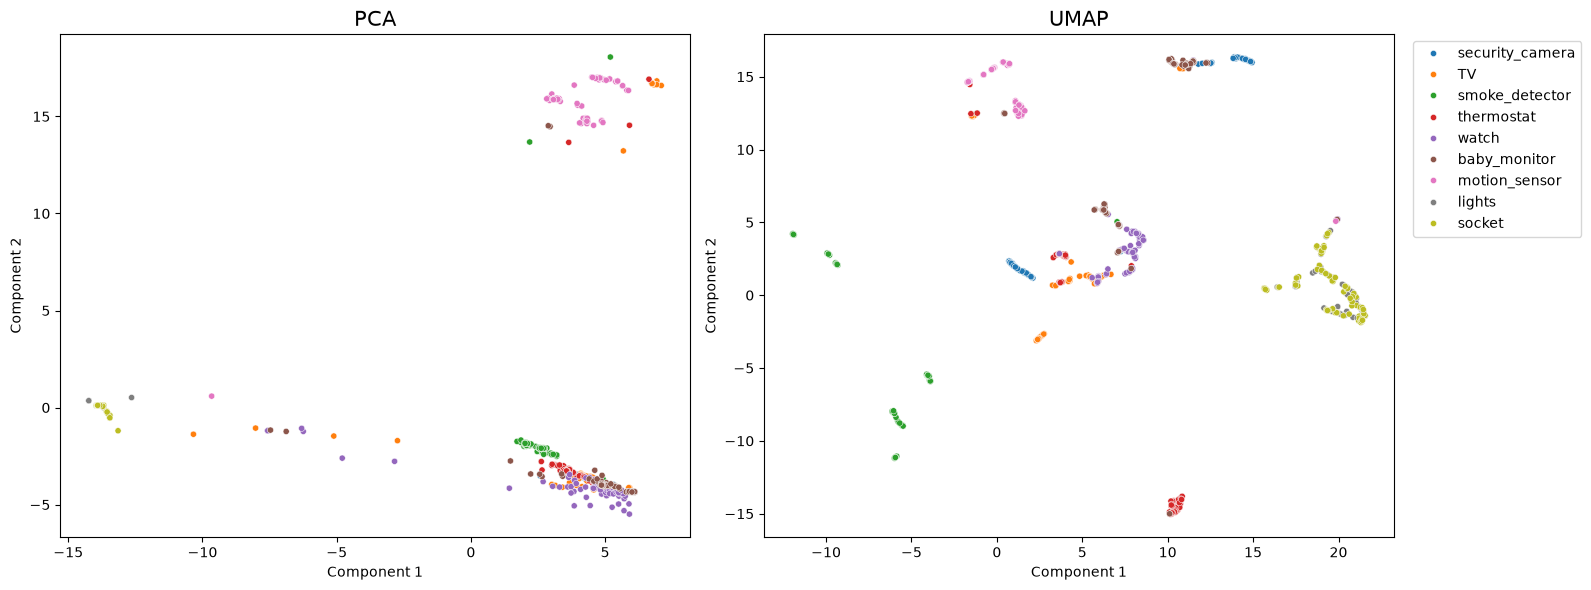

In [5]:
# 5. visualize
embeddings = {"PCA": X_pca, "UMAP": X_umap}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (name, emb) in zip(axes, embeddings.items()):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_train_raw, palette="tab10", s=20, ax=ax, legend=(name == "UMAP"))
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.set_title(name, size=15)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 6. PCA vs UMAP
PCA only explains about 65% of the variance with 2 components and mostly shows a few large, spread-out blobs: smoke detectors, thermostats, watches, TVs and baby monitors all sit on top of each other in the bottom-right, and motion sensors are the only class that is somewhat separate. This is because PCA is linear and global, so the two components are driven by the few high-variance (heavy-tailed) traffic features, not by what makes the devices different. UMAP gives much more information about the structure: smoke detectors, thermostats, security cameras, motion sensors and sockets each form their own tight clusters (some split into several sub-clusters, probably different traffic sessions), while TV, watch and baby monitor still overlap in the middle, and lights mix with sockets. So UMAP suggests that most devices are separable non-linearly, and it already points to TV/watch/baby_monitor and lights/socket as the hard pairs. Since UMAP is local, distances between clusters should not be interpreted.

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

### 1. Pre-analysis reflection
Tree-based ensembles split each feature on a threshold, so they are invariant to any monotonic transformation of the inputs. Scaling, standardization, normalization or log transforms change nothing about the splits, so we skip them. Outliers in the inputs are also less of a problem because a split only depends on the ordering of the values. The only required step is to make every input numeric. Here all 297 features are already numeric (int/float, no missing values), so the only encoding needed is the `LabelEncoder` on the outcome from Part 1. One-hot encoding of the outcome is not needed because sklearn handles multi-class labels internally.

In [6]:
# no scaling for trees; all inputs are already numeric, only the outcome needed encoding (done in Part 1)
print(X_train.dtypes.value_counts())

# same CV object for every model in Parts 2-4 (stratified since it is multi-class)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

# same max_depth candidates for both models, 3 values per hyperparameter
max_depths = [3, 6, 10]
param_grid_gb = {"max_depth": max_depths, "learning_rate": [0.01, 0.1, 0.3]}
param_grid_rf = {"max_depth": max_depths, "max_features": ["sqrt", "log2", 0.3]}

int64      217
float64     80
Name: count, dtype: int64


In [7]:
# helper: fit grid search, time it, evaluate on reporting set
results = {}

def run_search(model, param_grid, name):
    search = GridSearchCV(model, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
    start = time()
    search.fit(X_train, y_train)
    fit_min = (time() - start) / 60

    y_pred = search.predict(X_report)
    acc = accuracy_score(y_report, y_pred)
    results[name] = {"best_params": search.best_params_, "cv_accuracy": search.best_score_,
                     "report_accuracy": acc, "search_time_min": fit_min}
    print(f"{name} | best params: {search.best_params_}")
    print(f"CV accuracy = {search.best_score_:.3f} | reporting accuracy = {acc:.3f} | search time = {fit_min:.2f} min")
    return search, y_pred

def plot_cm(y_pred, name):
    cm = confusion_matrix(y_report, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"{name} Confusion Matrix (reporting set)", size=15)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    print(classification_report(y_report, y_pred, target_names=le.classes_, digits=3))

Gradient Boosting | best params: {'learning_rate': 0.1, 'max_depth': 3}
CV accuracy = 0.890 | reporting accuracy = 0.689 | search time = 1.36 min


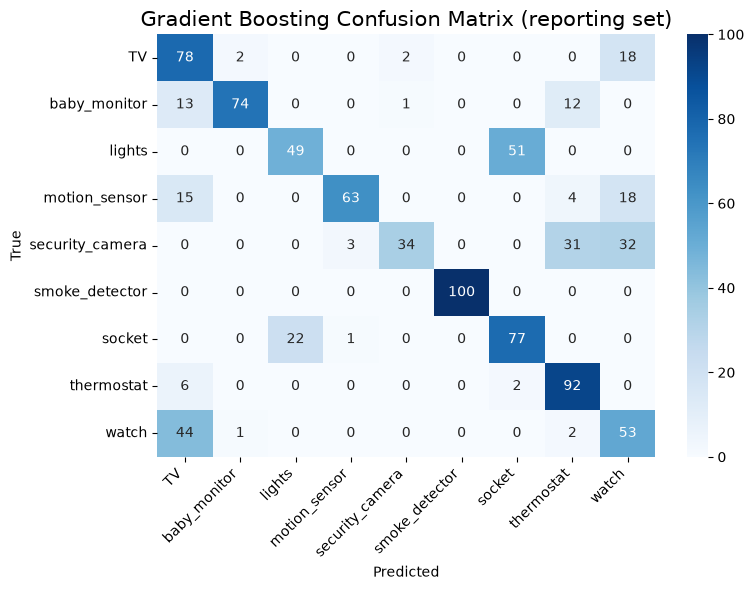

                 precision    recall  f1-score   support

             TV      0.500     0.780     0.609       100
   baby_monitor      0.961     0.740     0.836       100
         lights      0.690     0.490     0.573       100
  motion_sensor      0.940     0.630     0.754       100
security_camera      0.919     0.340     0.496       100
 smoke_detector      1.000     1.000     1.000       100
         socket      0.592     0.770     0.670       100
     thermostat      0.652     0.920     0.763       100
          watch      0.438     0.530     0.480       100

       accuracy                          0.689       900
      macro avg      0.744     0.689     0.687       900
   weighted avg      0.744     0.689     0.687       900



In [8]:
# Gradient Boosting
gb_search, gb_pred = run_search(GradientBoostingClassifier(random_state=seed), param_grid_gb, "Gradient Boosting")
plot_cm(gb_pred, "Gradient Boosting")

Random Forest | best params: {'max_depth': 10, 'max_features': 'log2'}
CV accuracy = 0.888 | reporting accuracy = 0.681 | search time = 0.04 min


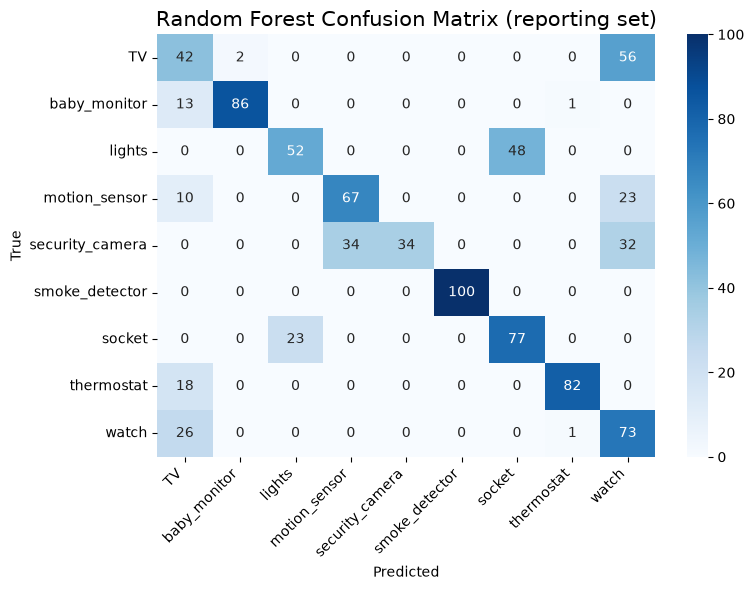

                 precision    recall  f1-score   support

             TV      0.385     0.420     0.402       100
   baby_monitor      0.977     0.860     0.915       100
         lights      0.693     0.520     0.594       100
  motion_sensor      0.663     0.670     0.667       100
security_camera      1.000     0.340     0.507       100
 smoke_detector      1.000     1.000     1.000       100
         socket      0.616     0.770     0.684       100
     thermostat      0.976     0.820     0.891       100
          watch      0.397     0.730     0.514       100

       accuracy                          0.681       900
      macro avg      0.745     0.681     0.686       900
   weighted avg      0.745     0.681     0.686       900



In [9]:
# Random Forest
rf_search, rf_pred = run_search(RandomForestClassifier(random_state=seed), param_grid_rf, "Random Forest")
plot_cm(rf_pred, "Random Forest")

In [10]:
# CV accuracy (~0.89) >> reporting accuracy (~0.69), so check if train and reporting come from different distributions
from scipy.stats import ks_2samp

ks = pd.Series({c: ks_2samp(X_train[c], X_report[c]).statistic for c in X_train.columns}).sort_values(ascending=False)
print(f"features with KS statistic > 0.3: {(ks > 0.3).sum()} / {len(ks)}")
ks.head(10)

features with KS statistic > 0.3: 82 / 297


/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:2610: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  outputs = ufunc(*args, out=...)


packet_size_A_max               0.690000
packet_size_A_var               0.680000
packet_size_A_stdev             0.680000
bytes                           0.674444
suffix_is_empty_char_value      0.673333
bytes_B                         0.671111
packet_inter_arrivel_B_sum      0.663333
suffix_is_else                  0.662222
packet_inter_arrivel_B_stdev    0.646667
packet_inter_arrivel_B_var      0.646667
dtype: float64

### Which devices are easiest / hardest?
Both models get very similar overall accuracy on the reporting set (GB 0.689, RF 0.681). **Smoke detectors** are perfectly classified by both (100/100), and **thermostats** and **baby monitors** are also easy (recall ≈ 0.75–0.92, precision ≥ 0.95 for baby_monitor). The hard classes are the same ones UMAP showed overlapping. **TV vs watch** get confused in both directions (GB predicts 44 watches as TV and 18 TVs as watch), **lights vs socket** too (51 lights predicted as socket), and **security cameras** have the worst recall (0.34): they are mostly predicted as thermostat or watch. Security cameras do have very high precision, though, so when the model says "camera" it is almost always right.

There is also a large gap between CV accuracy (~0.89) and reporting accuracy (~0.69). The KS check above shows that 82 of 297 features have clearly different distributions in the reporting set (e.g. `bytes`, `packet_size_A_max`, `packets`). So the reporting captures were likely collected under different conditions, and the models overfit to session-specific traffic volume. This is a dataset shift, not a leakage issue, and it also explains why CV overestimates performance.

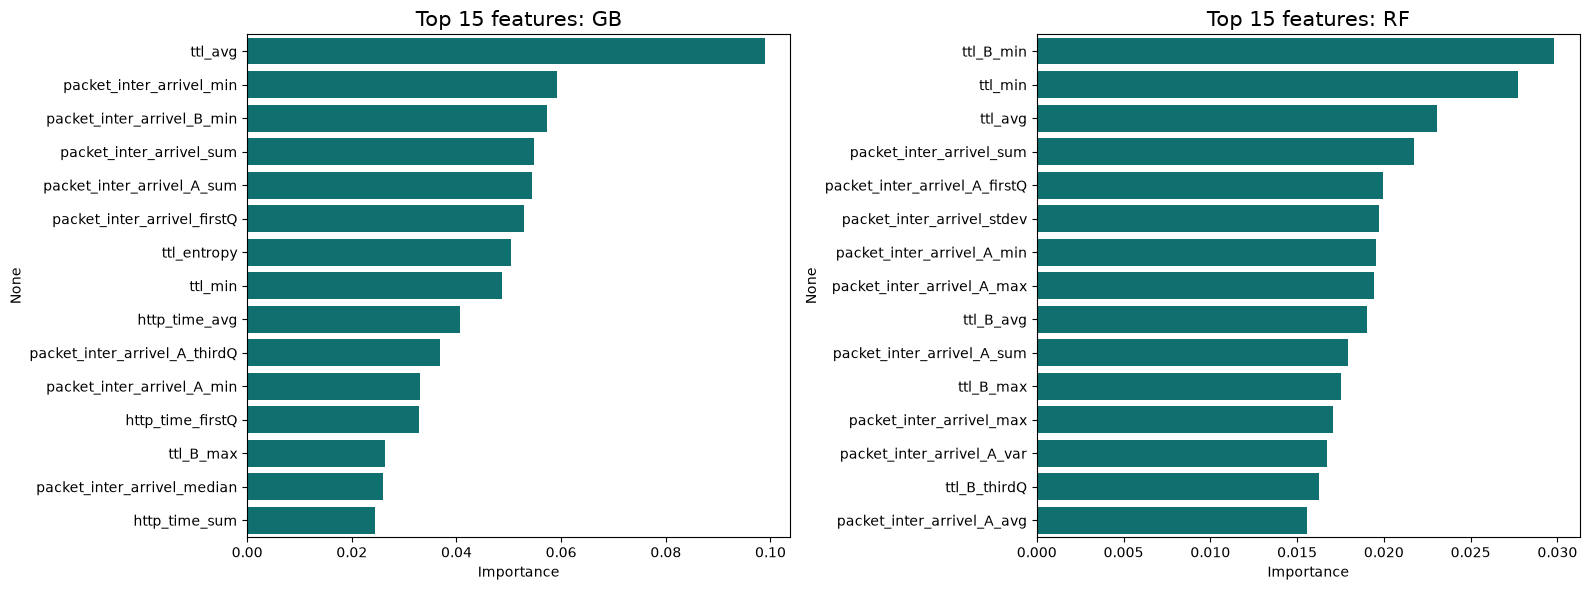

In [11]:
# 5. feature importance
imp = pd.DataFrame({"GB": gb_search.best_estimator_.feature_importances_,
                    "RF": rf_search.best_estimator_.feature_importances_}, index=X_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, m in zip(axes, ["GB", "RF"]):
    top = imp[m].sort_values(ascending=False).head(15)
    sns.barplot(x=top.values, y=top.index, ax=ax, color="teal")
    ax.set_title(f"Top 15 features: {m}", size=15)
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

In [12]:
# quantitative comparison of the two importance vectors
from scipy.stats import spearmanr

cosine = imp["GB"] @ imp["RF"] / (np.linalg.norm(imp["GB"]) * np.linalg.norm(imp["RF"]))
rho = spearmanr(imp["GB"], imp["RF"]).statistic
top20_gb = set(imp["GB"].nlargest(20).index)
top20_rf = set(imp["RF"].nlargest(20).index)
print(f"cosine similarity = {cosine:.3f}")
print(f"spearman rank corr = {rho:.3f}")
print(f"top-20 overlap = {len(top20_gb & top20_rf)}/20 -> {sorted(top20_gb & top20_rf)}")
print(f"share of total importance in top 10: GB = {imp['GB'].nlargest(10).sum():.2f}, RF = {imp['RF'].nlargest(10).sum():.2f}")

cosine similarity = 0.629
spearman rank corr = 0.871
top-20 overlap = 8/20 -> ['packet_inter_arrivel_A_min', 'packet_inter_arrivel_A_sum', 'packet_inter_arrivel_sum', 'ttl_B_max', 'ttl_B_min', 'ttl_avg', 'ttl_max', 'ttl_min']
share of total importance in top 10: GB = 0.55, RF = 0.22


### Feature importance discussion
**Qualitatively**, both models rely on the same two families of features: **TTL** (time to live: `ttl_avg`, `ttl_min`, `ttl_B_min`, ...) and **packet inter-arrival time** (`packet_inter_arrivel_*` min/sum/firstQ). Both make sense as device "fingerprints". TTL depends mostly on the device's OS/network stack, and inter-arrival time reflects how often the device talks (a smoke detector pings rarely, a camera streams constantly). They also do not depend much on how much traffic a session had, which fits with the size-based features (`bytes`, `packets`) being the ones that shift the most between train and reporting.

**Quantitatively**, the rank correlation is high (Spearman ρ = 0.87), so the overall ordering of features is similar, but the cosine similarity is only 0.63 and only 8 of the top-20 features overlap. The difference is in how the importance is *distributed*: GB puts 55% of the total importance in its top 10 features (`ttl_avg` alone ≈ 0.10), while RF spreads it out (top 10 ≈ 22%). This is expected. Boosting greedily picks the single best feature at each step and keeps reusing it, while RF's `max_features="log2"` forces each split to choose from a random subset, so correlated features (`ttl_min` vs `ttl_B_min`, `_sum` vs `_A_sum`) share the credit.

In [13]:
# 6. baseline: 9 balanced classes -> random guessing ~ 1/9
dummy = DummyClassifier(strategy="uniform", random_state=seed).fit(X_train, y_train)
print(f"theoretical baseline = {1/len(le.classes_):.3f}")
print(f"uniform dummy reporting accuracy = {accuracy_score(y_report, dummy.predict(X_report)):.3f}")

theoretical baseline = 0.111
uniform dummy reporting accuracy = 0.101


### Reflection vs random guessing
With 9 balanced classes (100 per class), random guessing gives an expected accuracy of 1/9 ≈ **11.1%**, not 50% (the uniform `DummyClassifier` gets 10.1%). Both ensembles reach ~68–69% on the reporting set, about **6× better than chance**, so they clearly learn real device signatures, even with the distribution shift. Still, ~30% error is too high for a security setting, mainly because of the TV/watch, lights/socket and security camera confusions.

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

### 1. HistGradientBoosting vs GradientBoosting
- **Main differences:** `GradientBoostingClassifier` looks at every unique value of every feature to find the best split, so its cost grows with the number of samples, O(n_features × n_samples) per node (plus sorting). `HistGradientBoostingClassifier` first bins each feature into at most 255 integer bins (`max_bins`), then builds the trees on those bins. On top of that it has native support for missing values and categorical features, built-in early stopping, multi-threading, and it is designed for large datasets (n_samples > ~10,000). It also grows trees leaf-wise, controlled by `max_leaf_nodes` (default 31) together with `max_depth`. In the classic implementation `max_depth` is the main control.
- **Why binning is faster:** after binning, a split is found by building a histogram of the gradients/hessians per bin and scanning only ≤255 bin boundaries instead of every sorted sample value, so the cost per node becomes O(n_features × n_bins) instead of O(n_features × n_samples). Histograms are cheap to build (one pass over the data), the integer bins use less memory, and the "subtraction trick" (child histogram = parent − sibling) means only one child histogram has to be computed at each split.

Hist Gradient Boosting | best params: {'learning_rate': 0.01, 'max_depth': 6}
CV accuracy = 0.879 | reporting accuracy = 0.688 | search time = 1.09 min


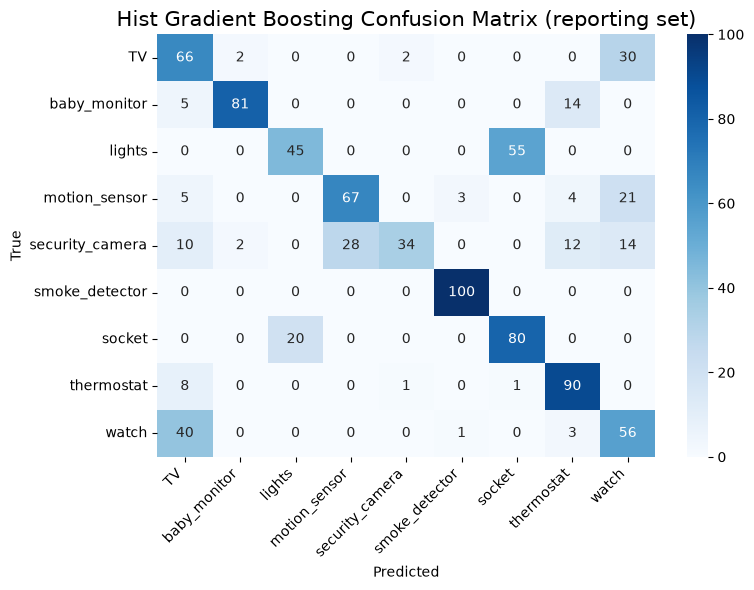

                 precision    recall  f1-score   support

             TV      0.493     0.660     0.564       100
   baby_monitor      0.953     0.810     0.876       100
         lights      0.692     0.450     0.545       100
  motion_sensor      0.705     0.670     0.687       100
security_camera      0.919     0.340     0.496       100
 smoke_detector      0.962     1.000     0.980       100
         socket      0.588     0.800     0.678       100
     thermostat      0.732     0.900     0.807       100
          watch      0.463     0.560     0.507       100

       accuracy                          0.688       900
      macro avg      0.723     0.688     0.682       900
   weighted avg      0.723     0.688     0.682       900



In [14]:
# same param_grid and cv object as Gradient Boosting in Part 2
hgb_search, hgb_pred = run_search(HistGradientBoostingClassifier(random_state=seed), param_grid_gb, "Hist Gradient Boosting")
plot_cm(hgb_pred, "Hist Gradient Boosting")

In [15]:
pd.DataFrame(results).T.loc[["Gradient Boosting", "Hist Gradient Boosting"]]

,best_params,cv_accuracy,report_accuracy,search_time_min
Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3}",0.89,0.688889,1.360953
Hist Gradient Boosting,"{'learning_rate': 0.01, 'max_depth': 6}",0.878889,0.687778,1.094574


### 4. Reflection
On this dataset, HistGB was only modestly faster (1.09 vs 1.36 min for the same 9×5 grid), and predictive performance is basically the same (reporting accuracy 0.688 vs 0.689, CV 0.879 vs 0.890), with the same hard classes (security camera, TV/watch, lights/socket). The speedup is small because the dataset is tiny (720 samples per fold): with < 1,000 samples, most features have fewer than 255 unique values anyway, so binning saves little. Also, the 9-class problem means HistGB still fits 9 trees per iteration, and parallelizing both the grid search and HistGB's own threads competes for the same CPU cores. The benefit of histograms grows with the number of samples, so on the full network traffic data (millions of flows) HistGB would be the clear choice. The trade-off is that binning loses some precision in the split thresholds, but here that had no noticeable effect on accuracy.

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


### 1. Preprocessing reflection
Unlike trees, neural networks are trained with gradient descent on weighted sums of the inputs, so preprocessing matters:
- **Scaling/standardization**: features on very different scales (here bytes in the millions vs binary flags) make some weights dominate and slow down or destabilize training, so we standardize.
- **Handling heavy tails/outliers**: many traffic features (sums, variances, byte counts) are extremely right-skewed. A plain `StandardScaler` fit on the training set mapped some reporting values to more than 10⁹ standard deviations away from the mean, which saturates the network (with only `StandardScaler`, reporting accuracy was ~0.18). Since all features are ≥ 0, we apply `log1p` before standardizing to compress the tails.
- **Encoding**: the outcome is already label-encoded; `MLPClassifier` handles the softmax/one-hot internally.
- All transformations go inside the `Pipeline` so they are refit on each CV training fold (no leakage).

In [16]:
# log1p tames the heavy tails (all features >= 0), then standardize
# both steps live inside the pipeline so they are refit on each CV training fold (no leakage)
mlp_pipe = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(max_iter=300, early_stopping=True, random_state=seed))
])

# 9 combos: {1, 2, 3} hidden layers x {32, 64, 128} units per layer
param_grid_mlp = {"mlp__hidden_layer_sizes": [(u,) * l for l in [1, 2, 3] for u in [32, 64, 128]]}
param_grid_mlp

{'mlp__hidden_layer_sizes': [(32,),
  (64,),
  (128,),
  (32, 32),
  (64, 64),
  (128, 128),
  (32, 32, 32),
  (64, 64, 64),
  (128, 128, 128)]}

MLP | best params: {'mlp__hidden_layer_sizes': (128,)}
CV accuracy = 0.844 | reporting accuracy = 0.557 | search time = 0.04 min


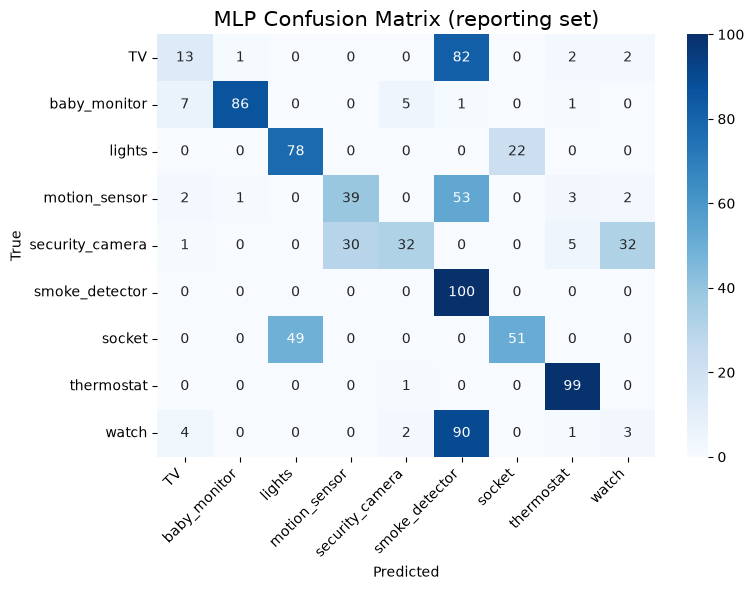

                 precision    recall  f1-score   support

             TV      0.481     0.130     0.205       100
   baby_monitor      0.977     0.860     0.915       100
         lights      0.614     0.780     0.687       100
  motion_sensor      0.565     0.390     0.462       100
security_camera      0.800     0.320     0.457       100
 smoke_detector      0.307     1.000     0.469       100
         socket      0.699     0.510     0.590       100
     thermostat      0.892     0.990     0.938       100
          watch      0.077     0.030     0.043       100

       accuracy                          0.557       900
      macro avg      0.601     0.557     0.530       900
   weighted avg      0.601     0.557     0.530       900

epochs until early stop: 33


In [17]:
mlp_search, mlp_pred = run_search(mlp_pipe, param_grid_mlp, "MLP")
plot_cm(mlp_pred, "MLP")
print("epochs until early stop:", mlp_search.best_estimator_["mlp"].n_iter_)

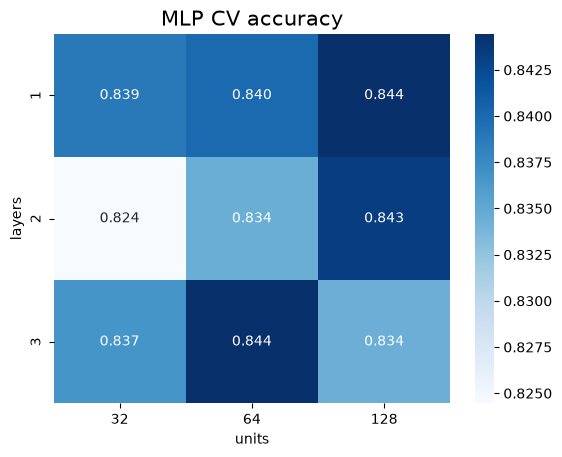

In [18]:
# cv accuracy for each architecture
cv_res = pd.DataFrame(mlp_search.cv_results_)
cv_res["layers"] = cv_res["param_mlp__hidden_layer_sizes"].apply(len)
cv_res["units"] = cv_res["param_mlp__hidden_layer_sizes"].apply(lambda t: t[0])
sns.heatmap(cv_res.pivot(index="layers", columns="units", values="mean_test_score"), annot=True, fmt=".3f", cmap="Blues")
plt.title("MLP CV accuracy", size=15)
plt.show()

In [19]:
# final comparison across all models
summary = pd.DataFrame(results).T
summary[["cv_accuracy", "report_accuracy", "search_time_min"]] = summary[["cv_accuracy", "report_accuracy", "search_time_min"]].astype(float).round(3)
summary

,best_params,cv_accuracy,report_accuracy,search_time_min
Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3}",0.890,0.689,1.361
Random Forest,"{'max_depth': 10, 'max_features': 'log2'}",0.888,0.681,0.038
Hist Gradient Boosting,"{'learning_rate': 0.01, 'max_depth': 6}",0.879,0.688,1.095
MLP,"{'mlp__hidden_layer_sizes': (128,)}",0.844,0.557,0.042


### 3. Comparison and reflection
The best MLP is a single hidden layer with 128 units, but all 9 architectures score in a narrow CV range (0.824–0.844), so depth/width matter little here. Early stopping ended training after ~33 epochs, well below the 300-epoch limit. In CV, the MLP (0.844) is slightly below the ensembles (~0.88–0.89), but on the reporting set it drops much more: **0.557 vs ~0.68–0.69**. It completely fails on watches (recall 0.03) and TVs (0.13), and it over-predicts smoke detectors (precision 0.31). This shows that the MLP is much more sensitive to the distribution shift between training and reporting. Trees only care about the ordering of a feature relative to a threshold, while the MLP's output changes continuously with the magnitude of every (shifted) input, even after the log transform. It was, however, very fast to tune (~0.04 min, similar to RF).

**Complexity and interpretability:** RF and GB give feature importances that directly told us *why* they work (TTL and inter-arrival times act as device fingerprints), and each tree can be inspected. The MLP has thousands of weights with no direct interpretation, needs careful preprocessing, and was less robust. For this tabular, heterogeneous, heavy-tailed dataset, the tree ensembles are both the more accurate and the more interpretable choice. Among them, **Random Forest** gives almost the same accuracy as Gradient Boosting at a fraction of the tuning time (0.04 vs 1.36 min).

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Our main challenge was that every model scored ~0.88 in cross-validation but only ~0.69 (and the first MLP only 0.18) on the reporting set. We initially assumed this was a bug in our code (e.g., label encoding or column order) and spent time re-checking it before realizing that the reporting data itself had a different distribution. This slowed down the parts that depended on those results (the discussions and the MLP preprocessing). In the next lab, we will check right away that the training and reporting sets have similar distributions (e.g., a quick KS test or summary-statistics comparison) and share it with the group before anyone starts modeling.